# T-11 PM2.5 短期預測基準：持續性預測 vs 多元線性迴歸

**目的：**建立 AirSleuth ⑤ Analytics Engine 的短期預測基準，回答「未來 1、3、6 小時 PM2.5 會是多少」。

**資料：**環境部國家測站小時值（`data/raw/moenv/`，用 `python -m scripts.backfill_moenv --days 60` 取得），臺中 6 站、高雄 12 站。
**方法：**`src/analytics/forecast.py`。依時間切分，前 75% 訓練、後 25% 測試（不隨機切，避免偷看未來）。
**比較：**持續性預測（未來 = 現在）vs 多元線性迴歸（MLR，特徵：PM2.5 現值與延遲值、6 小時平均、濕度、溫度、風的 u/v 分量、雨量、時段）。

In [1]:
import os, sys, glob, warnings
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
os.chdir(ROOT); sys.path.insert(0, str(ROOT)); warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.dates as mdates
from zoneinfo import ZoneInfo
from src.analytics import forecast as fc

plt.rcParams.update({"font.sans-serif": ["Microsoft JhengHei", "Noto Sans CJK TC", "sans-serif"],
                     "axes.unicode_minus": False, "figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e5e1",
                     "grid.linewidth": 0.6, "axes.edgecolor": "#52514e", "text.color": "#0b0b0b",
                     "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
                     "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb"})
BLUE, ORANGE, INK2 = "#2a78d6", "#eb6834", "#52514e"
FIG = ROOT / "notebooks" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
CITIES = ["臺中市", "高雄市"]

def load(city):
    df = pd.concat([pd.read_csv(f, dtype={"siteid": str}) for f in glob.glob(str(ROOT / "data/raw/moenv" / city / "*.csv.gz"))])
    df["time"] = pd.to_datetime(df["time"]).dt.tz_convert("Asia/Taipei")
    return df.drop_duplicates(["siteid", "time"])

data = {c: load(c) for c in CITIES}
for c, d in data.items():
    print(f"{c}: {d['siteid'].nunique()} 站、{len(d)} 筆小時資料，{d['time'].min():%Y-%m-%d} ～ {d['time'].max():%Y-%m-%d}")

臺中市: 6 站、8530 筆小時資料，2026-08-20 ～ 2026-10-19
高雄市: 12 站、17093 筆小時資料，2026-08-20 ～ 2026-10-19


## 1. 各預測時距的誤差

In [2]:
res = pd.concat([fc.evaluate(d, horizons=(1, 3, 6)).assign(city=c) for c, d in data.items()])
table = res.pivot_table(index=["city", "horizon_h"], columns="model", values=["MAE", "AQI_hit"])
table[("MAE", "MLR 改善")] = 1 - table[("MAE", "MLR")] / table[("MAE", "persistence")]
table.round(3)

AQI_hit                MAE                   
model              MLR persistence    MLR persistence MLR 改善
city horizon_h                                              
臺中市  1           0.847       0.840  2.828       2.965  0.046
     3           0.790       0.781  3.746       3.976  0.058
     6           0.754       0.729  4.427       4.864  0.090
高雄市  1           0.819       0.798  3.141       3.380  0.070
     3           0.787       0.741  3.970       4.570  0.131
     6           0.766       0.703  4.494       5.396  0.167

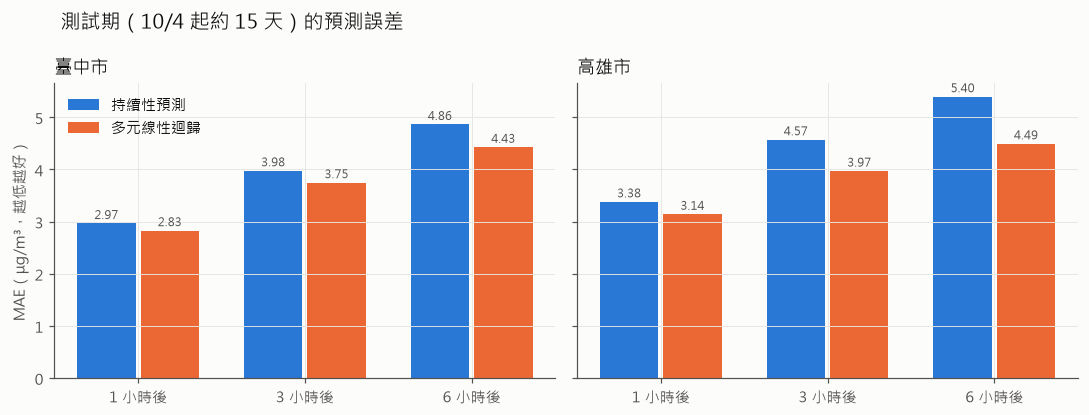

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, c in zip(axes, CITIES):
    r = res[res.city == c]
    x = np.arange(3); w = 0.38
    for i, (m, color, label) in enumerate([("persistence", BLUE, "持續性預測"), ("MLR", ORANGE, "多元線性迴歸")]):
        v = r[r.model == m].sort_values("horizon_h")["MAE"].to_numpy()
        bars = ax.bar(x + (i - 0.5) * w, v, width=w - 0.03, color=color, label=label)
        ax.bar_label(bars, fmt="%.2f", fontsize=8, color=INK2, padding=2)
    ax.set_xticks(x, ["1 小時後", "3 小時後", "6 小時後"]); ax.set_title(c, loc="left", fontsize=12)
axes[0].set_ylabel("MAE（μg/m³，越低越好）"); axes[0].legend(frameon=False, loc="upper left")
fig.suptitle("測試期（10/4 起約 15 天）的預測誤差", x=0.06, ha="left", fontsize=13)
fig.tight_layout(); fig.savefig(FIG / "t11_fig1_mae.png", dpi=160)

## 2. 預測範例：一個測站一週的 3 小時預測

({'MAE': 5.895888723159128,
  'RMSE': 8.280419546220932,
  'AQI_hit': 0.7615384615384615,
  'n': 130},
 {'MAE': 5.915384615384616,
  'RMSE': 8.432081593533118,
  'AQI_hit': 0.7384615384615385,
  'n': 130})

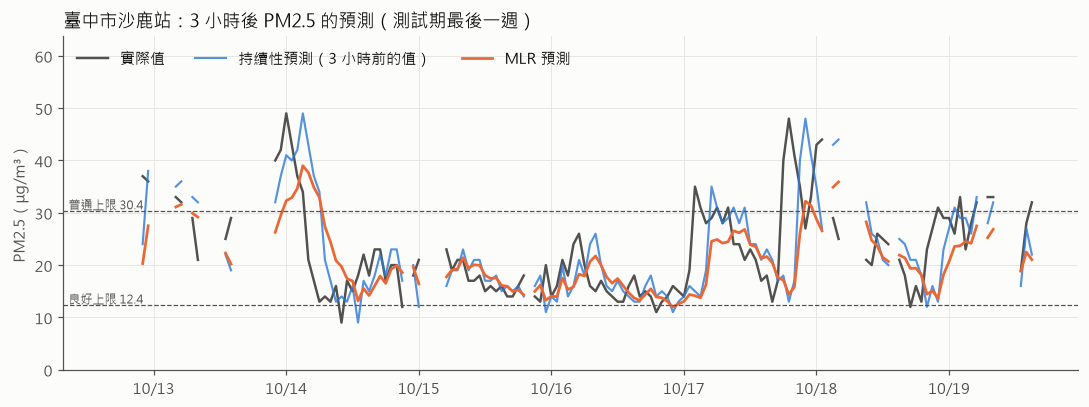

In [4]:
c, site = "臺中市", "沙鹿"
d = data[c]
h = 3
f = fc.build_features(d, h).dropna(subset=fc.FEATURES + ["target"])
train, test, cut = fc.split_by_time(f)
model = fc.MLR().fit(train, train["target"])
sid = d.loc[d.sitename == site, "siteid"].iloc[0]
t = test[test.siteid == sid].copy()
t["pred"] = model.predict(t); t["valid_time"] = t["time"] + pd.Timedelta(hours=h)
t = t[t["valid_time"] >= t["valid_time"].max() - pd.Timedelta(days=7)]
t = t.set_index("valid_time").reindex(pd.date_range(t["valid_time"].min(), t["valid_time"].max(), freq="h"))
t.index.name = "valid_time"; t = t.reset_index()  # 缺資料的小時保留 NaN，線條會斷開，不會假裝有資料
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(t["valid_time"], t["target"], color=INK2, linewidth=1.6, label="實際值")
ax.plot(t["valid_time"], t["pm25"], color=BLUE, linewidth=1.4, alpha=0.8, label="持續性預測（3 小時前的值）")
ax.plot(t["valid_time"], t["pred"], color=ORANGE, linewidth=1.8, label="MLR 預測")
for b in fc.AQI_PM25_BOUNDS[:2]:
    ax.axhline(b, color=INK2, linewidth=0.8, linestyle="--")
ax.annotate("良好上限 12.4", (0.005, 12.4), xycoords=("axes fraction", "data"), va="bottom", fontsize=8, color=INK2)
ax.annotate("普通上限 30.4", (0.005, 30.4), xycoords=("axes fraction", "data"), va="bottom", fontsize=8, color=INK2)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%d", tz=ZoneInfo("Asia/Taipei")))
ax.set_ylim(0, np.nanmax(t[["target", "pm25", "pred"]].to_numpy()) * 1.3)
ax.set_ylabel("PM2.5（μg/m³）"); ax.legend(frameon=False, loc="upper left", ncol=3)
ax.set_title(f"{c}{site}站：3 小時後 PM2.5 的預測（測試期最後一週）", loc="left", fontsize=12)
fig.tight_layout(); fig.savefig(FIG / "t11_fig2_example.png", dpi=160)
ok = t["target"].notna() & t["pred"].notna()
fc.metrics(t.loc[ok, "target"], t.loc[ok, "pred"]), fc.metrics(t.loc[ok, "target"], t.loc[ok, "pm25"])

## 3. 模型係數（3 小時預測）：可以解釋的模型

In [5]:
coef = pd.DataFrame({c: fc.MLR().fit(*(lambda tr: (tr, tr["target"]))(
            fc.split_by_time(fc.build_features(d, 3).dropna(subset=fc.FEATURES + ["target"]))[0])).coefficients()
        for c, d in data.items()})
coef.round(3)

,臺中市,高雄市
intercept,13.264,16.159
pm25,0.398,0.359
pm25_lag1,0.041,0.057
pm25_lag2,-0.003,-0.003
pm25_lag3,-0.053,-0.020
pm25_mean6,0.402,0.368
rh,-0.060,-0.071
temp,-0.213,-0.262
wind_u,0.053,0.038
wind_v,0.082,-0.266


## 4. 小結

文字結論整理在 `docs/analysis/T-11_短期預測基準.md`。注意：測試期只有約 15 天、單一季節（秋季），不能代表冬季東北季風期間的表現。